# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]   # Columns derived by ColdSense

n_alerts = int((df["ai_flag"] == 1).sum())

fault_rate_pct = round((df["confirmed_fault"] == 1).mean() * 100, 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()}")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault count"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46


,fault count
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*

The `ai_score` is quantitative, so colour intensity (colour gradient) is suitable to show different score values. The `ai_flag` is binary, so two distinct colours can represent alert and no alert. The flag loses the exact anomaly score and the degree of abnormality, including how close a reading is to the 0.5 threshold, which the score preserves.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

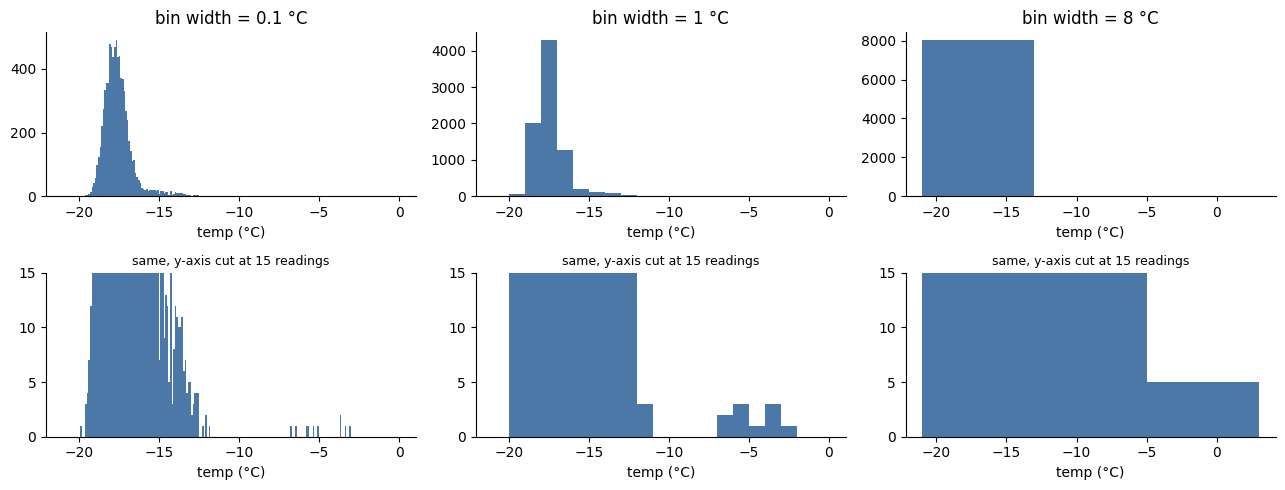

Warm tail visible at bin widths: [0.1]
Number of readings warmer than -8°C: 10


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))

for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)

        if top:
            ax.set_ylim(0, top)
            ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else:
            ax.set_title(f"bin width = {w} °C")

        ax.set_xlabel("temp (°C)")

plt.tight_layout()
plt.show()

# TODO answers
warm_tail_visible_bins = [0.1]  # Verify from the bottom-row histogram
n_warm_readings = int((df["temp_c"] > -8).sum())

if ready(warm_tail_visible_bins, n_warm_readings):
    print("Warm tail visible at bin widths:", warm_tail_visible_bins)
    print("Number of readings warmer than -8°C:", n_warm_readings)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

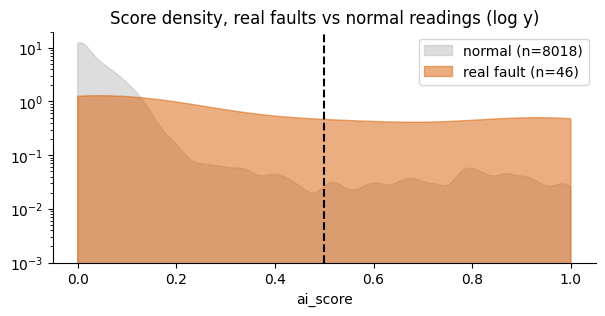

Clean score separation: False


In [4]:
xs = np.linspace(0, 1, 300)

fig, ax = plt.subplots(figsize=(7, 3))

for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(
        xs,
        stats.gaussian_kde(s)(xs),
        color=col,
        alpha=.5,
        label=f"{'real fault' if lab else 'normal'} (n={len(s)})"
    )

ax.axvline(0.5, color="k", ls="--")
ax.set_yscale("log")
ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score")
ax.legend()
ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False  # Check whether the two distributions overlap

if ready(scores_separate_faults):
    print("Clean score separation:", scores_separate_faults)

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*

A histogram is a parameterised algorithm because its appearance depends on settings such as bin width and the number of bins. Changing these settings can change how the distribution looks and whether unusual patterns are visible. I would tell my colleague that the 8 °C histogram may hide small groups of unusual temperature readings because its bins are too wide. We should examine smaller bin widths and the original temperature values before concluding that there are no anomalies.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[
    (df.freezer_id == "FZ-P1") &
    (df.timestamp >= "2026-08-12 06:00") &
    (df.timestamp < "2026-08-12 16:00")
]

v = window["temp_c"].values

print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

# Z-score method
z_max = np.max(np.abs((v - np.mean(v)) / np.std(v, ddof=1)))

# IQR method
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*

The Z-score rule missed the temperature spike because of masking: the extreme reading increased the mean and standard deviation, making its own Z-score appear less unusual. The IQR rule detected it because quartiles are less affected by extreme values, so the upper fence remained low enough to identify the temperature spike as an outlier.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = ((flag) & (real)).sum()   # Alerts that were real faults
FP = ((flag) & (~real)).sum()  # Alerts on normal readings (false alarms)
FN = ((~flag) & (real)).sum()  # Real faults with no alert (missed)
TN = ((~flag) & (~real)).sum() # Normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame(
        [[TP, FN], [FP, TN]],
        index=["real fault", "normal"],
        columns=["alert", "no alert"]
    ))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1 = (2 * precision * recall / (precision + recall)
      if (precision + recall) > 0 else 0)

accuracy = (TP + TN) / (TP + FP + FN + TN)

flag_nothing_accuracy = (df["confirmed_fault"] == 0).mean()

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.2f}")
    print(f"accuracy of a detector that never raises an alert = {flag_nothing_accuracy:.2f}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 0.98
accuracy of a detector that never raises an alert = 0.99


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*

ColdSense has a precision of only 0.10 (10%), meaning that out of every 100 alerts, only 10 are actual faults and 90 are false alarms, resulting in unnecessary technician call-outs. Its recall is 0.35 (35%), meaning it detects only 35 out of every 100 actual faults and misses the remaining 65. Although its accuracy is 98%, a detector that never raises an alert achieves 99% accuracy. Therefore, ColdSense is not reliable enough to be trusted without human verification.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

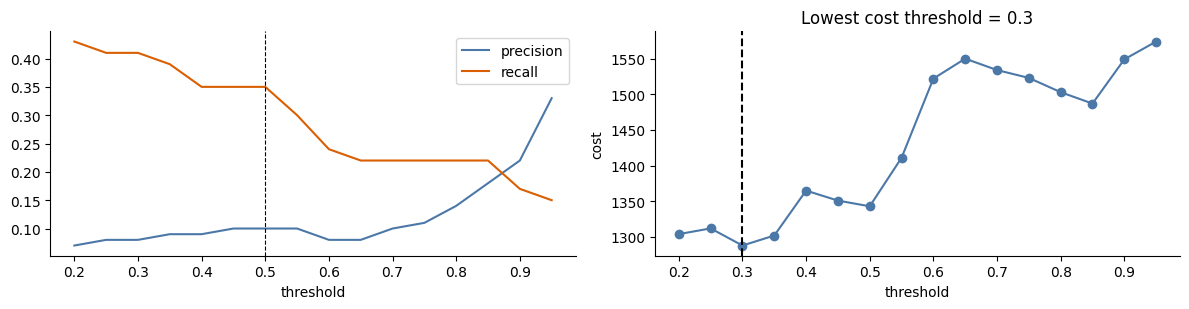

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)

sweep = pd.DataFrame({"threshold": grid})

sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & (~real)).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]

sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

# Calculate business cost
sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]

# Find the threshold with the lowest cost
best_threshold = sweep.loc[sweep["cost"].idxmin(), "threshold"]

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision")
    ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8)
    ax[0].legend()
    ax[0].set_xlabel("threshold")

    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o")
    ax[1].axvline(best_threshold, color="k", ls="--")
    ax[1].set_xlabel("threshold")
    ax[1].set_ylabel("cost")
    ax[1].set_title(f"Lowest cost threshold = {best_threshold}")

    plt.tight_layout()
    plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*

Even at the best threshold, recall may remain low because some actual faults receive low anomaly scores and are not detected by ColdSense. Lowering the threshold may increase false alarms, but it cannot reliably detect faults that the AI fails to recognise, so improving the anomaly detection model is also necessary.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

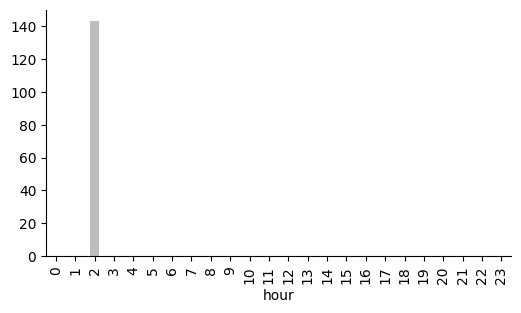

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]

fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY)
plt.show()

# Hour with the most false alarms
fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())

# Share of all false alarms occurring during that hour
fp_share_at_peak = (
    fp_rows.groupby("hour").size().max() / len(fp_rows)
)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(
    caught="sum",
    fault_hours="size"
)

caught["recall"] = (
    caught.caught / caught.fault_hours
).round(2)

display(caught)

# Fault type that ColdSense never catches
never_caught_type = caught.index[caught["caught"] == 0].tolist()

# Classification requires examining what the missed fault represents
anomaly_kind = None

if ready(never_caught_type):
    print("Fault type never caught:", never_caught_type)

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


Fault type never caught: ['sensor frozen']


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [ ]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = None       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

### 6d · Collective anomalies: a run of readings that is abnormal together

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]

df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(
    lambda s: 1.4826 * stats.median_abs_deviation(s)
)

# TODO completed
df["z_context"] = (
    (df["temp_c"] - df["hour_median"]) / df["hour_mad"]
)

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4

    found = df[real & ctx_flag & ~flag]

    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")

    display(found[
        ["timestamp", "freezer_id", "temp_c", "hour_median",
         "z_context", "ai_score", "fault_type"]
    ])

    print(
        f"False alarms at 02:00 under the context baseline: "
        f"{(ctx_flag & ~real & (df.hour == 2)).sum()} "
        f"(ColdSense: {(flag & ~real & (df.hour == 2)).sum()})"
    )

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

**(a)** The false alarms at 2 am are likely caused by normal temperature patterns that ColdSense incorrectly identifies as anomalies. The contextual baseline helps distinguish normal hourly temperature changes from actual faults. Hiring a night technician based only on these alerts could waste time and money because many of the alerts may not represent real problems.

**(b)** Vendor statement 5 is not fully reliable because a temperature reading can be normal in general but unusual for a particular freezer at a particular time. This is called a contextual anomaly. A chart should show the temperature over time along with the freezer's normal hourly baseline, anomaly score and alert threshold so that viewers can judge whether the alert is genuinely unusual.

**(c)** Vendor statement 4 is incorrect because it overlooks a fault involving a sequence of unusually constant temperature readings. This is a collective anomaly. A detector that scores readings one at a time cannot recognise unusual patterns across a sequence because it does not consider how readings behave together over time.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

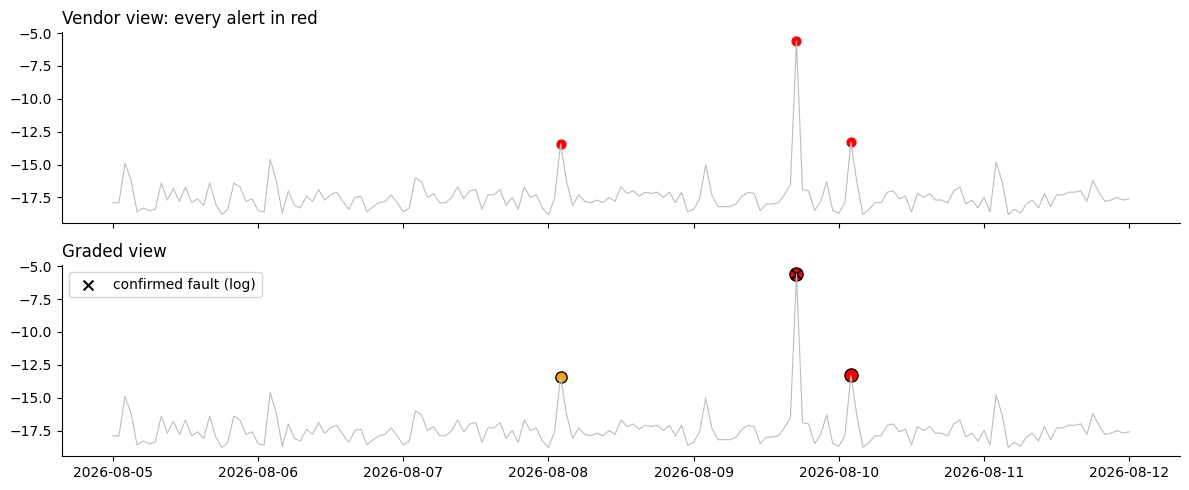

In [12]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""

    if score >= 0.9:
        return ("red", 90, "black")
    elif score >= 0.7:
        return ("orange", 65, "black")
    elif score >= 0.5:
        return ("yellow", 40, "grey")
    else:
        return ("lightgrey", 20, "none")


week = df[
    (df.freezer_id == "FZ-B2") &
    (df.timestamp.between("2026-08-05", "2026-08-12"))
]

if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)

    a = week[week.ai_flag == 1]

    ax[0].scatter(
        a.timestamp, a.temp_c,
        color="red", s=40
    )

    ax[0].set_title("Vendor view: every alert in red", loc="left")

    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)

    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)

        ax[1].scatter(
            r.timestamp, r.temp_c,
            color=col, s=size, edgecolors=edge
        )

    f_ = week[week.confirmed_fault == 1]

    ax[1].scatter(
        f_.timestamp, f_.temp_c,
        marker="x", color="k", s=50,
        label="confirmed fault (log)"
    )

    ax[1].legend(loc="upper left")
    ax[1].set_title("Graded view", loc="left")

    plt.tight_layout()
    plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

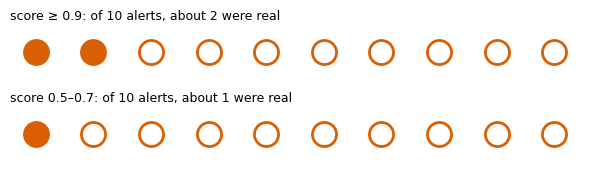

In [13]:
band_hi = df[df.ai_score >= 0.9]

band_lo = df[
    (df.ai_score >= 0.5) &
    (df.ai_score < 0.7)
]

# TODO completed
real_per_10_hi = int(round(
    band_hi["confirmed_fault"].mean() * 10
))

real_per_10_lo = int(round(
    band_lo["confirmed_fault"].mean() * 10
))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))

    for a_, k, lab in zip(
        ax,
        [real_per_10_hi, real_per_10_lo],
        ["score ≥ 0.9", "score 0.5–0.7"]
    ):
        for i in range(10):
            a_.scatter(
                i, 0, s=300,
                color=ACCENT if i < k else "white",
                edgecolors=ACCENT,
                linewidths=2
            )

        a_.axis("off")
        a_.set_title(
            f"{lab}: of 10 alerts, about {k} were real",
            loc="left", fontsize=9
        )

    plt.tight_layout()
    plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

**(a)** Showing every alert as a red dot gives all alerts equal visual salience, making the chart crowded and hiding unusual patterns such as the frozen H2 sensor readings. This can cause inattentional blindness, where technicians focus on the obvious red alerts and fail to notice an important but less visually prominent problem.

**(b)** Instead of saying that a high anomaly score guarantees a fault, we should use frequency framing: "Among every 10 alerts with a score of 0.9 or higher, approximately ___ were confirmed as real faults, compared with approximately ___ out of 10 alerts with scores between 0.5 and 0.7."

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[
    (df.freezer_id == "FZ-B1") &
    (df.hour == 14) &
    (df.confirmed_fault == 0)
]["temp_c"]

mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

# Standard error of the baseline mean
se = sd / np.sqrt(n)

# Z-score using standard deviation
z_sd = (new_reading - mu) / sd

# Z-score using standard error
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

# Correct measure for judging a single new reading
correct_z = "SD"

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
**Standard Deviation (SD):** SD measures how much individual temperature readings vary or spread around the mean.

**Standard Error (SE):** SE measures how accurately the sample mean estimates the true population mean.

**Corrected vendor statement 8:** The new reading of -15.9°C should be compared with the baseline mean using standard deviation (SD), not standard error (SE), because we are evaluating an individual temperature reading rather than the uncertainty of the mean.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Reject",   # High accuracy is misleading; never-alert detector gets 99%
    2: "Reject",   # 2 am false alarms do not mean most faults happen then
    3: "Accept",   # Assuming the fault-type table confirms all 10 were caught
    4: "Reject",   # FZ-H2 shows a suspicious flat temperature pattern
    5: "Reject",   # -14°C must be judged using freezer and time context
    6: "Reject",   # Anomaly score is not a probability
    7: "Reject",   # 0.5 is not necessarily the lowest-cost threshold
    8: "Reject",   # SD, not SE, should judge a single reading
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject    7
Accept    1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

I would design an anomaly review dashboard with the following five parts:

1. **Main view:** A temperature-over-time line chart showing anomaly scores using different colours and marker sizes according to their severity. Confirmed faults should be highlighted separately.

2. **Context:** Show each freezer's normal temperature range, hourly baseline and recent temperature history so technicians can identify contextual and collective anomalies.

3. **Alert queue:** Display alerts ranked by severity and business risk, including freezer ID, timestamp, anomaly score and fault type.

4. **Verification tools:** Allow technicians to inspect individual readings, compare them with historical patterns, view maintenance logs and mark alerts as real faults or false alarms.

5. **Evaluation:** Display precision, recall, false alarms, missed faults and the performance of different thresholds. This helps the team understand whether ColdSense is actually useful.

The dashboard should help technicians prioritise important alerts instead of treating every AI alert as equally important. Human verification should remain part of the final decision.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*

### 1. Automation bias

Before checking the data, I found the vendor's accuracy claim most convincing because 97.9% sounded very reliable. However, after comparing it with precision and recall, I realised that high accuracy can be misleading when most readings are normal. Without the maintenance log, it would have been difficult to identify which alerts were false and which actual faults were missed.

### 2. Who sets the threshold?

FreshKart's cold-chain lead, operations team and management should jointly decide the alert threshold because it affects both food safety and technician workload. The dashboard should show precision, recall, false alarms, missed faults and the estimated cost at different thresholds so they can make an informed decision.

### 3. Missing ground truth

If faults that nobody inspected remain unlabeled, some actual faults may be incorrectly counted as normal readings. This can make precision and recall misleading because the system's predictions are being compared with incomplete ground truth. A review workflow should allow technicians to investigate alerts, record actual findings and regularly update the maintenance log with verified labels.

### 4. Designing against over-trust

I would use different colours and marker sizes to represent different anomaly score levels instead of showing every alert as a red dot. I would also allow technicians to click an alert to view its temperature history, normal baseline and maintenance records before deciding whether it is a real fault. This would encourage verification instead of blindly trusting the AI.